# Check Each Subject

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from glhmm import io, utils


subject_id = 1
step = 1
fs_features = 1 / step
K = 4 # num_state

data_root = r"C:\Users\pipo\Datasets-Docs\Multimodal Dataset for Mixed Emotion Recognition\preprocessed_GLHMM"

subject_dir = os.path.join(data_root, "subject_" + str(subject_id))
model_dir = os.path.join(subject_dir, "GLHMM_K4_noPCA")
input_path = "DMER_GLHMM_features.npz"


with np.load(
    os.path.join(subject_dir, input_path)) as data:
    X = data["X"]
    Y = data["Y"]
    video_ids = data["video_ids"]

with np.load(os.path.join(model_dir, "GLHMM_results.npz")) as data:
    Gamma = data["Gamma"]
    Xi = data["Xi"]
    FE = data["FE"]
    indices = data["indices"]
    
hmm = io.load_hmm(
    "GLHMM_model.pkl",
    directory=model_dir
)

vpath = hmm.decode(
    X=X,
    Y=Y,
    indices=indices,
    viterbi=True,
    serial=False
)

FO = utils.get_FO(Gamma, indices)

SR = utils.get_switching_rate(Gamma, indices)

LTmean, LTmed, LTmax = utils.get_life_times(
    vpath,
    indices
)

# Convert lifetime samples to seconds
LTmean = LTmean / fs_features
LTmed = LTmed / fs_features
LTmax = LTmax / fs_features

print("FO:", FO.shape)
print("SR:", SR.shape)
print("LTmean:", LTmean.shape)
print("Viterbi:", vpath.shape)

FO: (32, 4)
SR: (32, 4)
LTmean: (32, 4)
Viterbi: (651, 4)


c:\Users\pipo\miniconda3\envs\glhmm\Lib\site-packages\glhmm\auxiliary.py:355: RuntimeWarning: invalid value encountered in divide
  delta[t,:,:] = delta[t,:,:] / np.expand_dims(np.sum(delta[t,:,:],axis=1),axis=1)


In [310]:
Y.shape

(651, 18)

**Group Label**

In [311]:
trial_video_ids = []

for start, end in indices:

    ids = np.unique(video_ids[start:end])

    assert len(ids) == 1, "A trial contains multiple video IDs"

    trial_video_ids.append(int(ids[0]))

trial_video_ids = np.array(trial_video_ids)

condition_groups = {
    "Positive": np.where(
        (trial_video_ids >= 0) &
        (trial_video_ids <= 7)
    )[0],

    "Negative": np.where(
        (trial_video_ids >= 8) &
        (trial_video_ids <= 15)
    )[0],

    "Mixed": np.where(
        (trial_video_ids >= 16) &
        (trial_video_ids <= 31)
    )[0]
}

for condition, idx in condition_groups.items():
    print(condition, ":", len(idx), "trials")

Positive : 8 trials
Negative : 8 trials
Mixed : 16 trials


**State Plotting**

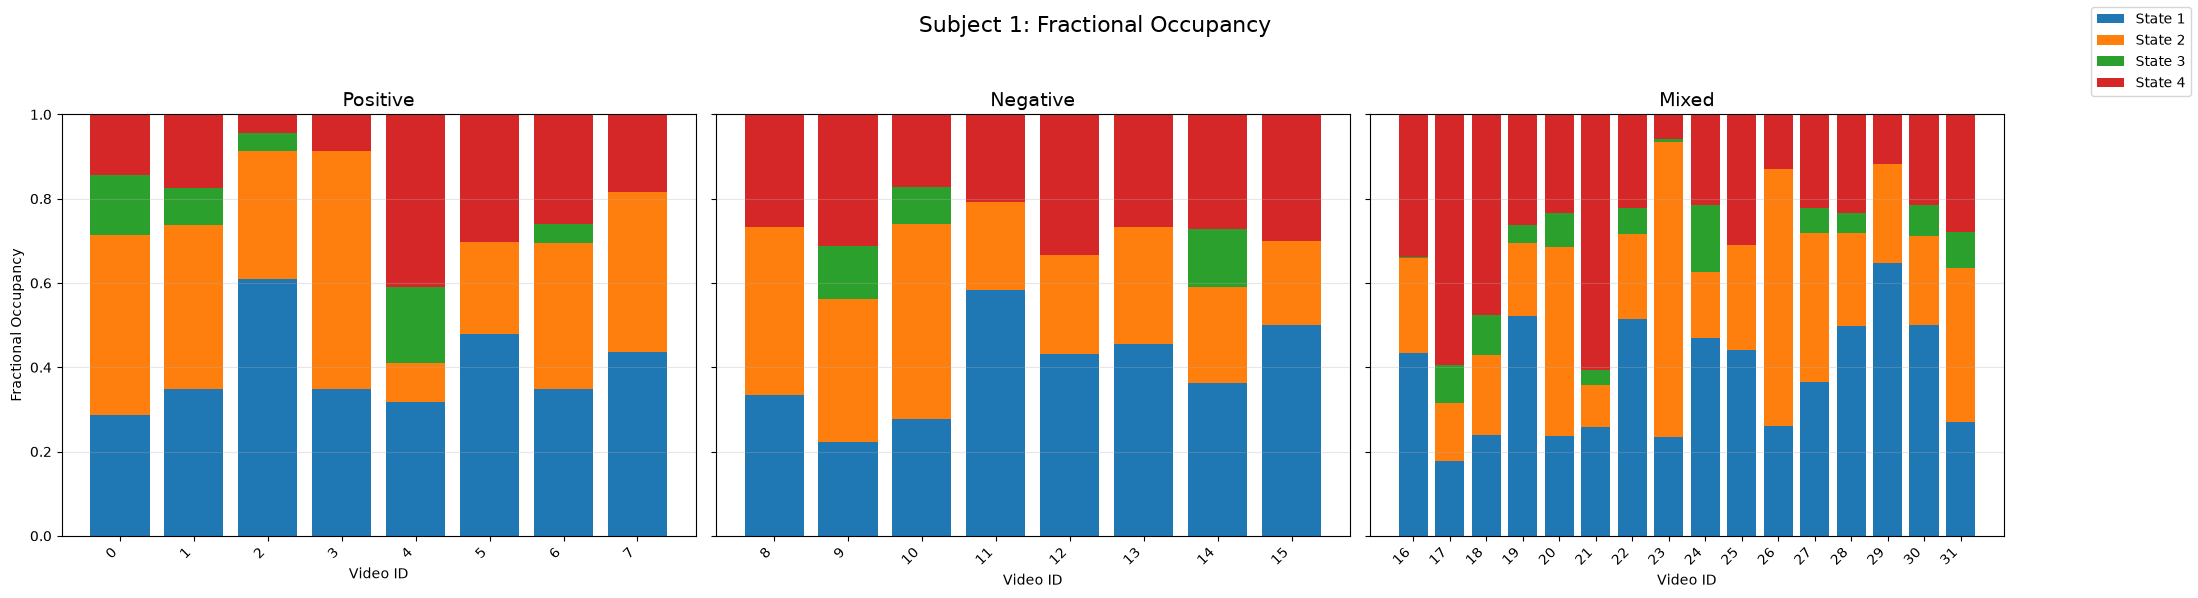

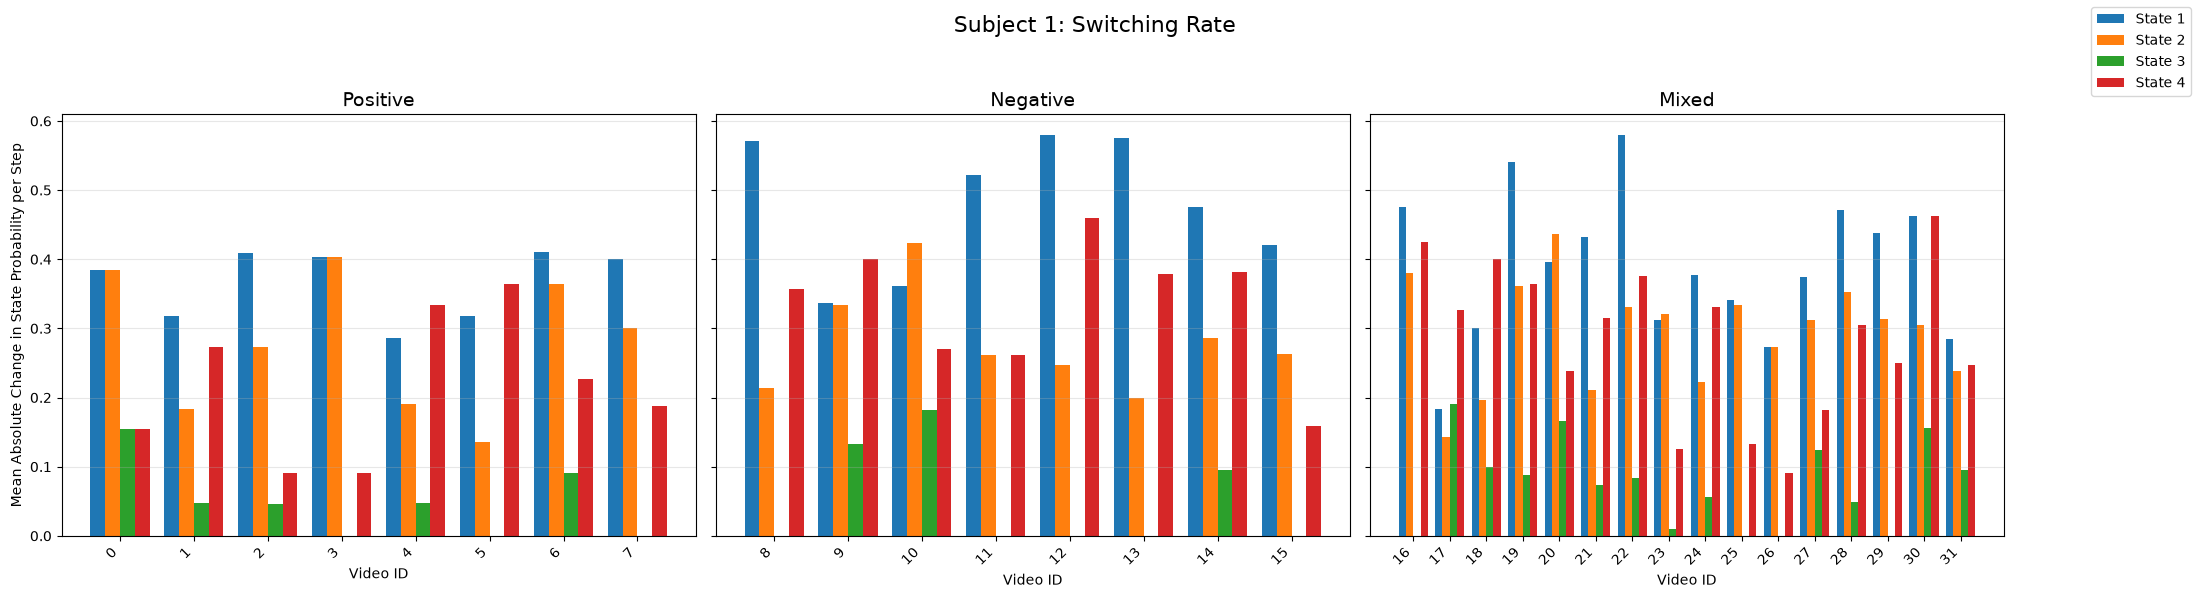

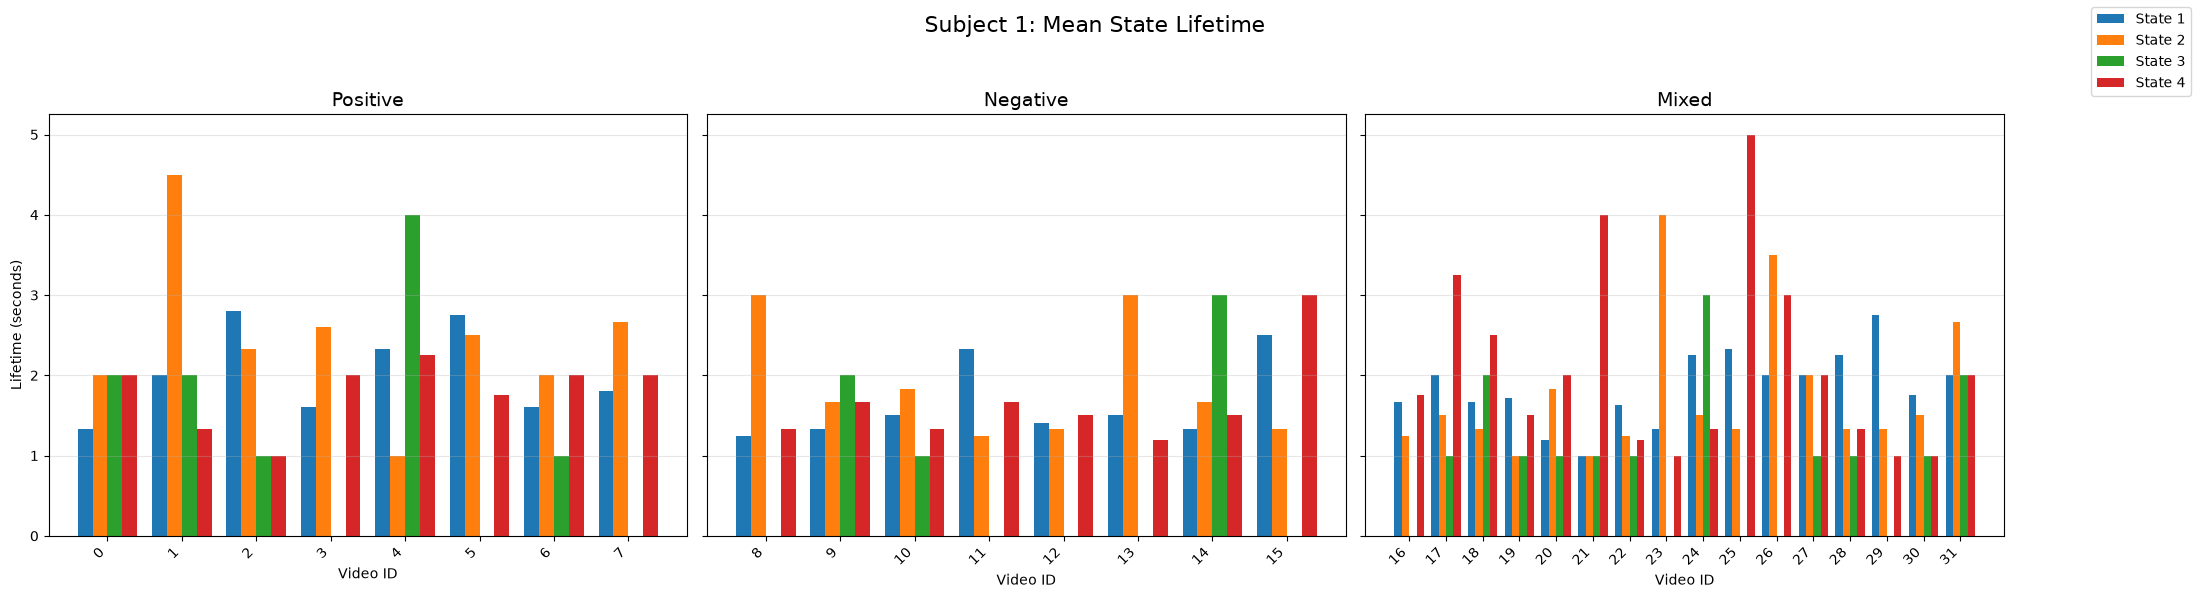

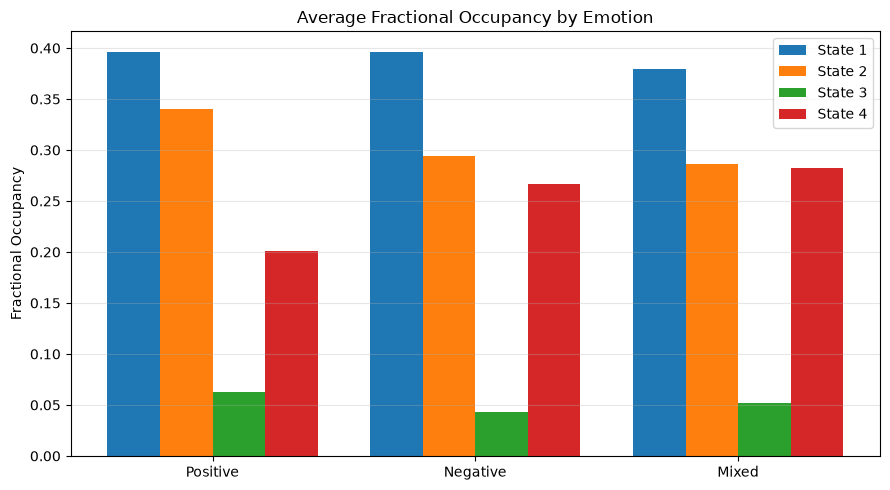

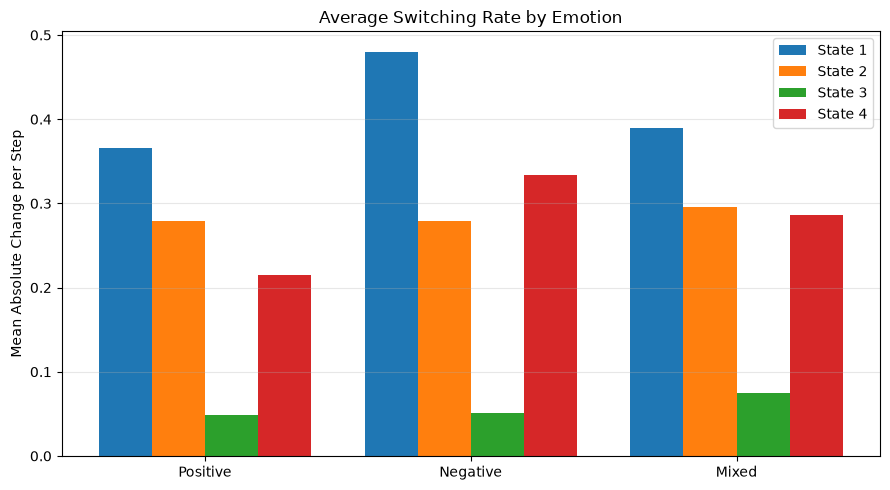

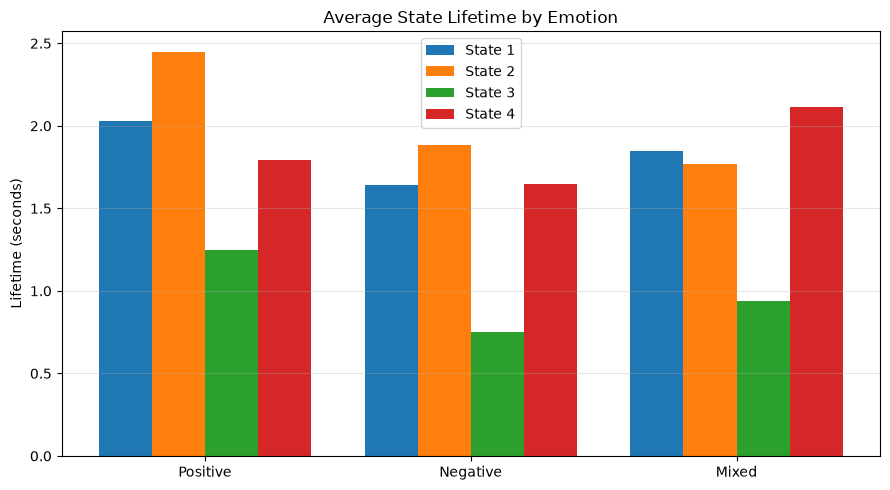

In [312]:
def plot_metric_by_condition(
    metric,
    condition_groups,
    trial_video_ids,
    title,
    ylabel,
    stacked=False
):
    metric = np.asarray(metric)
    fig, axes = plt.subplots(
        1, 3,
        figsize=(22, 6),
        sharey=True
    )

    n_states = metric.shape[1]
    colors = plt.cm.tab10.colors[:n_states]

    for ax, (condition, idx) in zip(
        axes,
        condition_groups.items()
    ):

        data = metric[idx, :]
        x = np.arange(len(idx))
        xlabels = trial_video_ids[idx]

        if stacked:
            bottom = np.zeros(len(idx))

            for s in range(n_states):

                ax.bar(
                    x,
                    data[:, s],
                    bottom=bottom,
                    label=f"State {s+1}",
                    color=colors[s]
                )

                bottom += data[:, s]

        else:

            width = 0.8 / n_states

            for s in range(n_states):

                ax.bar(
                    x + (s - (n_states - 1) / 2) * width,
                    data[:, s],
                    width=width,
                    label=f"State {s+1}",
                    color=colors[s]
                )

        ax.set_title(condition, fontsize=14)

        ax.set_xticks(x)

        ax.set_xticklabels(
            xlabels,
            rotation=45,
            ha="right"
        )

        ax.set_xlabel("Video ID")
        ax.grid(axis="y", alpha=0.3)

        if stacked:
            ax.set_ylim(0, 1)

    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper right"
    )

    fig.suptitle(title, fontsize=16)
    fig.tight_layout(rect=[0, 0, 0.92, 0.94])
    plt.show()
    
def plot_condition_average(metric, title, ylabel):

    condition_names = list(condition_groups.keys())

    condition_means = []

    for condition in condition_names:

        idx = condition_groups[condition]

        with np.errstate(invalid="ignore"):
            values = np.ma.masked_invalid(metric[idx])
            mean_values = np.ma.mean(values, axis=0).filled(np.nan)

        condition_means.append(mean_values)

    condition_means = np.array(condition_means)

    n_states = condition_means.shape[1]

    x = np.arange(len(condition_names))
    width = 0.8 / n_states

    plt.figure(figsize=(9, 5))

    for s in range(n_states):

        plt.bar(
            x + (s - (n_states - 1) / 2) * width,
            condition_means[:, s],
            width=width,
            label=f"State {s+1}"
        )

    plt.xticks(x, condition_names)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
    
# PLot funtional oppuancy
plot_metric_by_condition(
    FO,
    condition_groups,
    trial_video_ids,
    title=f"Subject {subject_id}: Fractional Occupancy",
    ylabel="Fractional Occupancy",
    stacked=True
)

# switching rate by condition
plot_metric_by_condition(
    SR,
    condition_groups,
    trial_video_ids,
    title=f"Subject {subject_id}: Switching Rate",
    ylabel="Mean Absolute Change in State Probability per Step",
    stacked=False
)

# Lifetime by condition

plot_metric_by_condition(
    LTmean,
    condition_groups,
    trial_video_ids,
    title=f"Subject {subject_id}: Mean State Lifetime",
    ylabel="Lifetime (seconds)",
    stacked=False
)
    
    
plot_condition_average(
    FO,
    "Average Fractional Occupancy by Emotion",
    "Fractional Occupancy"
)

plot_condition_average(
    SR,
    "Average Switching Rate by Emotion",
    "Mean Absolute Change per Step"
)

plot_condition_average(
    LTmean,
    "Average State Lifetime by Emotion",
    "Lifetime (seconds)"
)

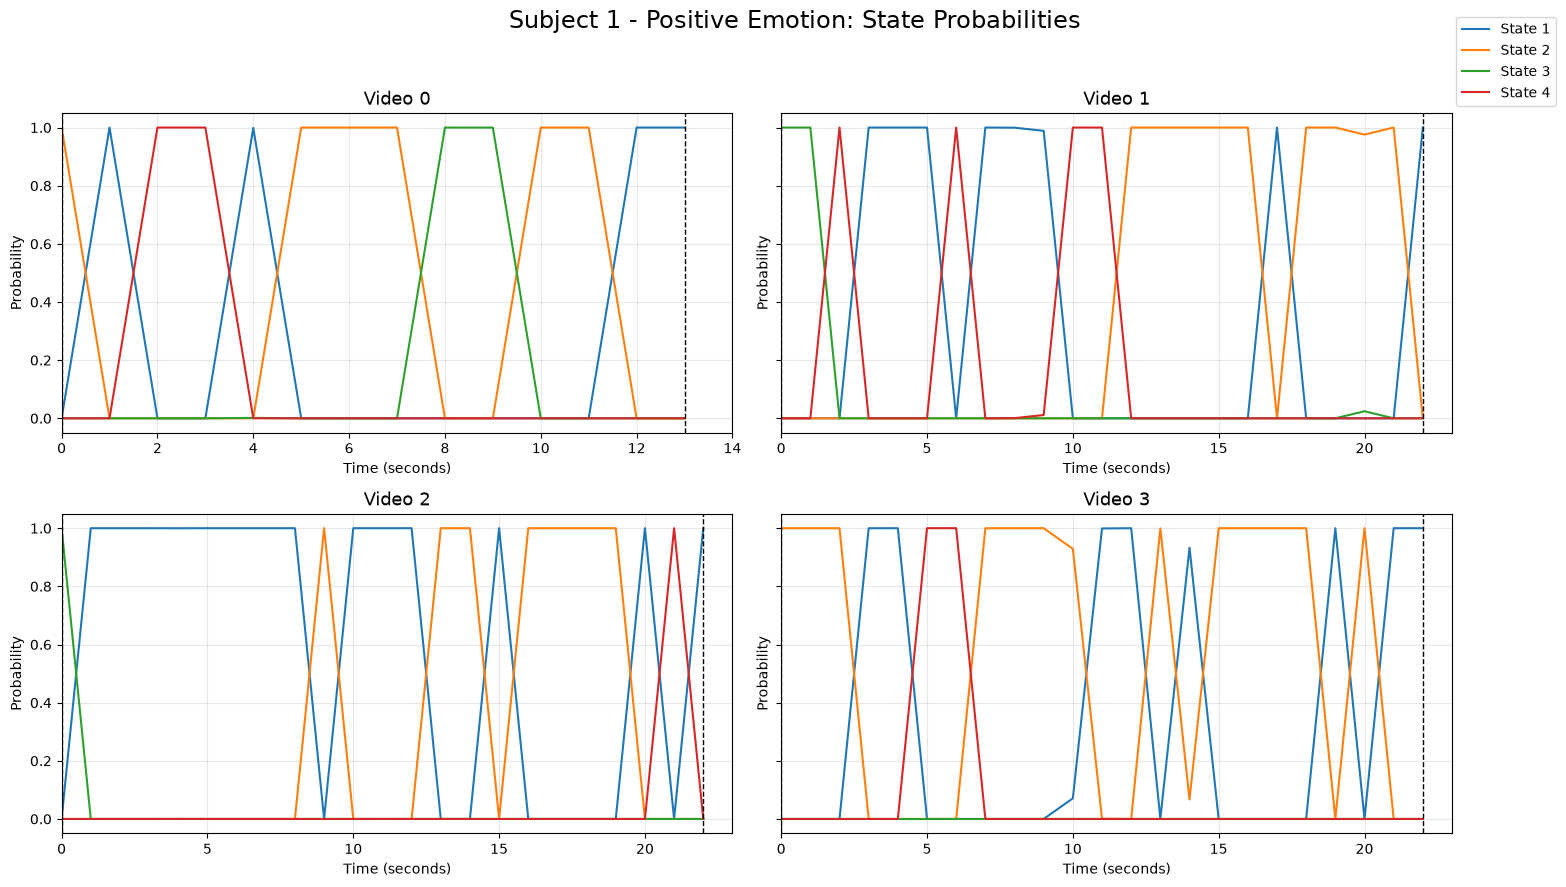

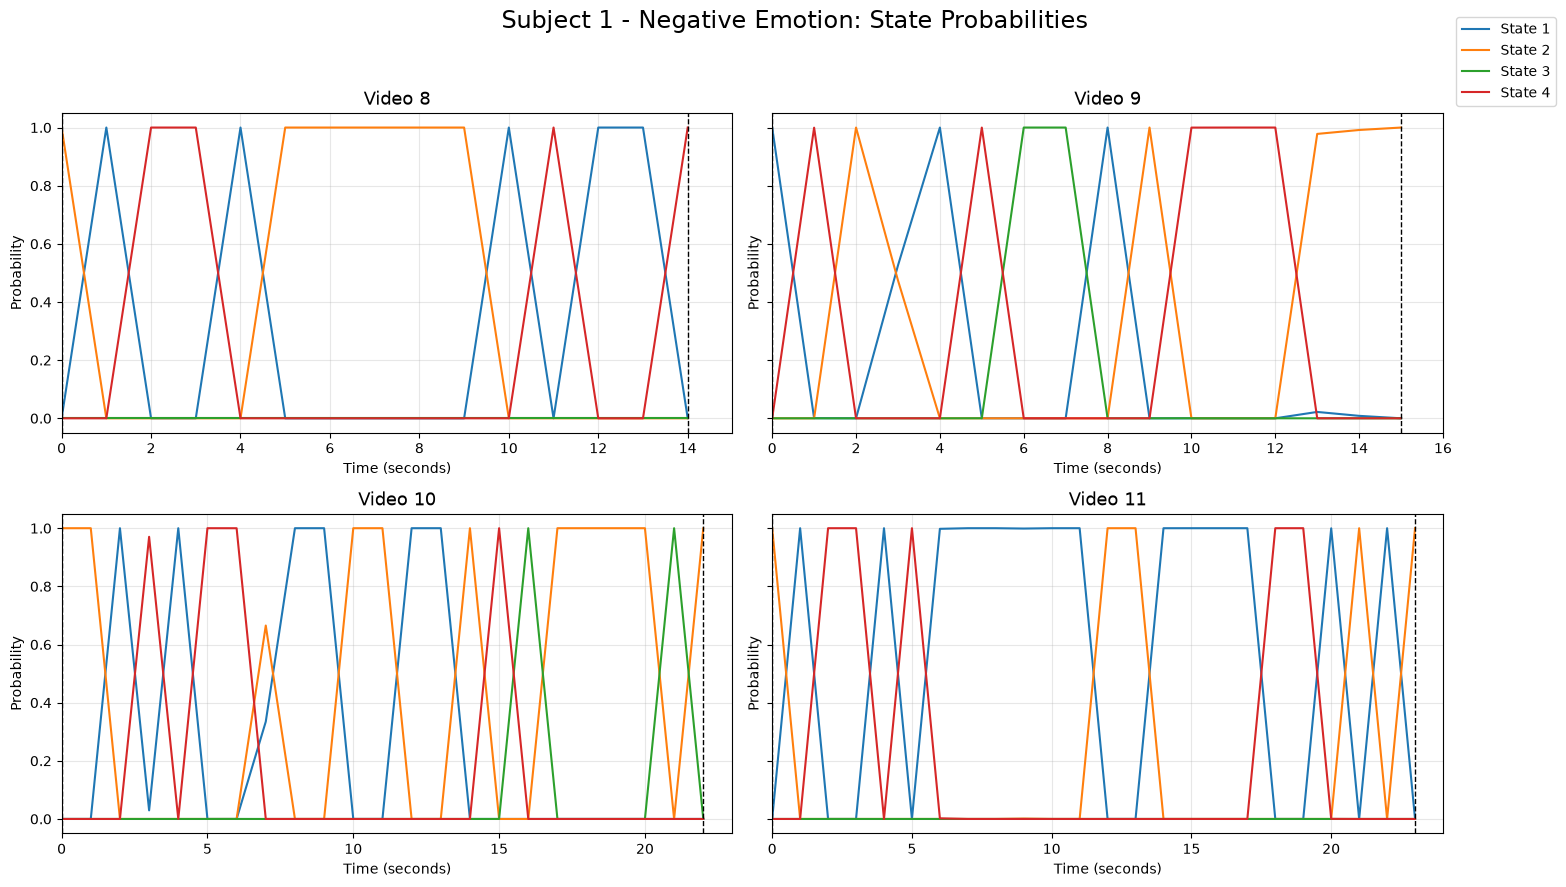

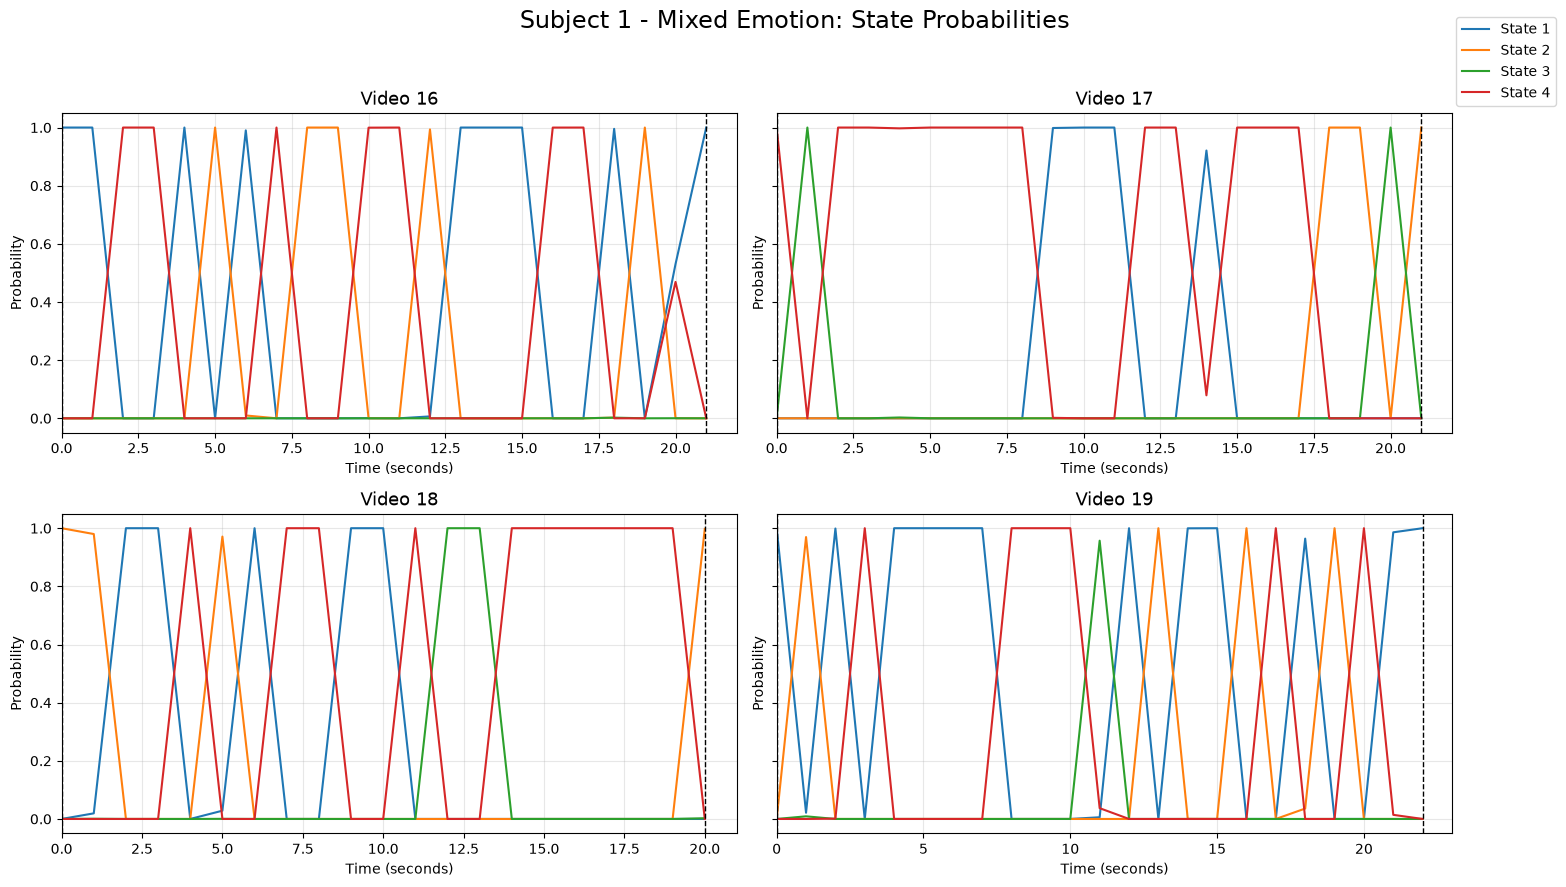

In [313]:
import numpy as np
import matplotlib.pyplot as plt


first_time = 8  # First valid feature at 8 seconds

emotion_trials = {
    "Positive": [0, 1, 2, 3],
    "Negative": [8, 9, 10, 11],
    "Mixed": [16, 17, 18, 19]
}

n_states = Gamma.shape[1]
colors = plt.cm.tab10.colors[:n_states]


for emotion, selected_videos in emotion_trials.items():

    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 9),
        sharey=True
    )

    axes = axes.flatten()

    for ax, vid in zip(axes, selected_videos):

        # Find trial corresponding to video ID
        trial_idx = np.where(trial_video_ids == vid)[0][0]

        start, end = indices[trial_idx]

        # State probabilities for this trial
        gamma_trial = Gamma[start:end, :]

        # Time axis
        times = np.arange(len(gamma_trial)) * step

        # Plot each state
        for k in range(n_states):

            ax.plot(
                times,
                gamma_trial[:, k],
                color=colors[k],
                linewidth=1.5,
                label=f"State {k+1}"
            )

        # First available feature and trial end
        ax.axvline(
            times[0],
            color="black",
            linestyle="--",
            linewidth=1
        )

        ax.axvline(
            times[-1],
            color="black",
            linestyle="--",
            linewidth=1
        )

        ax.set_title(f"Video {vid}", fontsize=13)

        ax.set_xlim(0, times[-1] + 1)
        ax.set_ylim(-0.05, 1.05)

        ax.grid(alpha=0.3)

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Probability")

    # Shared legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98)
    )

    fig.suptitle(
        f"Subject {subject_id} - {emotion} Emotion: State Probabilities",
        fontsize=17
    )

    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    plt.show()

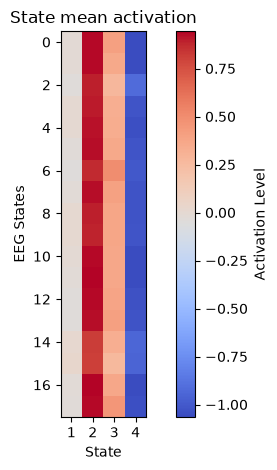

In [314]:
q = Y.shape[1]
state_means = np.zeros(shape=(q, K))
for k in range(K):
    state_means[:,k] = hmm.get_mean(k) # the state means in the shape (no. features, no. states)
state_FC = np.zeros(shape=(q, q, K))
for k in range(K):
    state_FC[:,:,k] = hmm.get_covariance_matrix(k=k) # the state covariance matrices in the shape (no. features, no. features, no. states)
    
plt.imshow(state_means,cmap=cmap, interpolation="none")
plt.colorbar(label='Activation Level') # Label for color bar
plt.title("State mean activation")
plt.xticks(np.arange(K), np.arange(1,K+1))
plt.gca().set_xlabel('State')
plt.gca().set_ylabel('EEG States')
plt.tight_layout()  # Adjust layout for better spacing
plt.show()

- For GSR,extracted:
1. Mean
2. Standard deviation
3. Slope
- For PPG:
1. Pulse rate
2. Standard deviatio

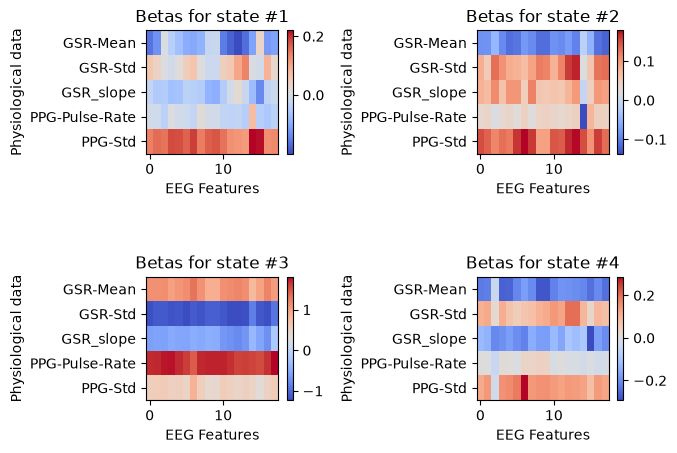

In [315]:
betas = hmm.get_betas()
cmap = "coolwarm"
ytick =["GSR-Mean", "GSR-Std", "GSR_slope","PPG-Pulse-Rate", "PPG-Std"]
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(betas[:,:,k], cmap=cmap,aspect='auto', interpolation='none')
    plt.colorbar()
    plt.ylabel('Physiological data')
    plt.yticks(np.arange(5), ytick)
    plt.xlabel('EEG Features')
    plt.title(f"Betas for state #{k+1}")
plt.subplots_adjust(hspace=1, wspace=1)
plt.show()

In [316]:
# import os
# import glob
# import numpy as np
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# from glhmm import glhmm, preproc, utils, graphics, spectral, io, statistics, auxiliary

# data_root = r"C:\Users\pipo\Datasets-Docs\Multimodal Dataset for Mixed Emotion Recognition\preprocessed_GLHMM"

# result_files = sorted(glob.glob(
#     os.path.join(
#         data_root,
#         "*",
#         "GLHMM_K4_noPCA",
#         "GLHMM_results.npz"
#     )
# ))

# qc_results = []

# for file_path in result_files:

#     subject_id = os.path.basename(
#         os.path.dirname(os.path.dirname(file_path))
#     )

#     with np.load(file_path) as data:
#         Gamma = data["Gamma"]
#         FE = data["FE"]
#         indices = data["indices"]

#     # Average probability of each state
#     occupancy = Gamma.mean(axis=0)

#     # Check posterior probabilities
#     gamma_error = np.max(
#         np.abs(Gamma.sum(axis=1) - 1)
#     )

#     # Check state usage (illustrative 1% threshold)
#     active_states = np.sum(occupancy > 0.01)

#     qc_results.append({
#         "Subject": subject_id,
#         "Samples": len(Gamma),
#         "Trials": len(indices),
#         "Active_States": active_states,
#         "Min_Occupancy": occupancy.min(),
#         "Max_Occupancy": occupancy.max(),
#         "Gamma_Error": gamma_error,
#         "Final_FE": np.asarray(FE).ravel()[-1],
#         "FE_Finite": np.isfinite(FE).all()
#     })

# qc_df = pd.DataFrame(qc_results)

# print("Models checked:", len(qc_df))
